# 2. Geospatial Exploratory Data Analysis

## 2.1 Geographical Data Overview

This section explores the geographical characteristics of the weather dataset.

The analysis focuses on geographical coordinates, location coverage, and the spatial distribution of weather observations across different countries.

**Objectives:**

- Examine latitude and longitude distributions.
- Identify the number of unique geographical locations.
- Verify the validity of geographical coordinates.
- Visualize the geographical distribution of locations.
- Understand the spatial coverage of the dataset.

In [12]:
# Standard Libraries
import sys
import importlib

# Project Configuration
sys.path.insert(0, str(__import__("pathlib").Path.cwd().parent))

from config import PROJECT_ROOT, RAW_DATA_PATH

# Data Libraries
import pandas as pd
import matplotlib.pyplot as plt

# Project Modules
import src.visualization
importlib.reload(src.visualization)

from src.visualization import (
    plot_geographical_distribution,
    plot_locations_per_country
)

In [13]:

# Load Raw Dataset
df = pd.read_csv(RAW_DATA_PATH)

# Display Basic Geographical Information
print(f"Total records: {len(df):,}")

print(
    "Unique geographical locations:",
    df[["country", "location_name"]].drop_duplicates().shape[0]
)

print("Unique countries:", df["country"].nunique())

print("\nLatitude Statistics:")
display(df["latitude"].describe())

print("\nLongitude Statistics:")
display(df["longitude"].describe())

Total records: 170,928
Unique geographical locations: 286
Unique countries: 211

Latitude Statistics:


count    170928.000000
mean         19.283424
std          24.373383
min         -41.300000
25%           4.050300
50%          17.250000
75%          40.400000
max          65.300000
Name: latitude, dtype: float64


Longitude Statistics:


count    170928.000000
mean         21.805043
std          65.766968
min        -175.200000
25%          -6.836100
50%          21.433300
75%          49.882200
max         179.220000
Name: longitude, dtype: float64

### 2.2 Spatial Distribution Visualization

In this section, geographical locations are visualized using their latitude and longitude coordinates.

A scatter plot is used to examine the spatial distribution of the dataset and identify the geographical areas covered by the available observations.

Each point represents one unique geographical location rather than an individual weather record.

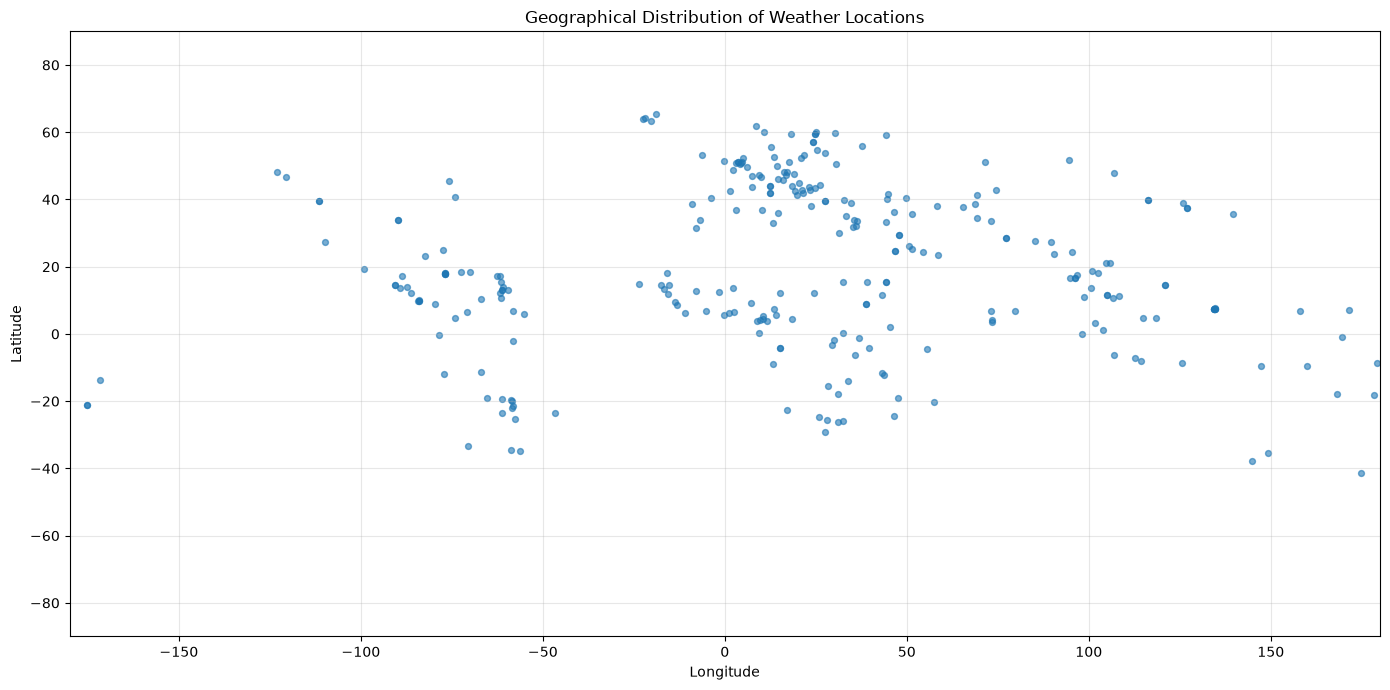

In [14]:
# Define output path
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Generate and save geographical distribution plot
plot_geographical_distribution(
    df,
    save_path=FIGURES_DIR / "geographical_distribution.png"
)

**Geographical Distribution — Key Findings**

The dataset contains 170,928 weather records distributed across 286 unique geographical locations in 211 countries.

The geographical coordinates cover a wide range of the globe:

- Latitude ranges from -41.30° to 65.30°.
- Longitude ranges from -175.20° to 179.22°.

The spatial visualization reveals the following observations:

- Weather locations are distributed across multiple continents.
- Europe shows relatively dense geographical coverage.
- Other regions exhibit varying levels of spatial coverage.
- The geographical distribution is not uniform across the globe.
- High-latitude polar regions are not represented in the observed latitude range.

**Important Observation:**

The number of unique locations is determined using the combination of country and location name rather than location name alone. This avoids incorrectly merging locations with identical names in different countries.

**Conclusion:**

The dataset provides broad geographical coverage, but the spatial distribution is uneven. This should be considered when performing geographical analysis and developing spatial machine learning models.

### 2.3 Geographical Coordinates Validation

This section evaluates the validity and consistency of geographical coordinates.

The analysis focuses on:

- Identifying coordinates outside valid latitude and longitude ranges.
- Detecting missing geographical coordinates.
- Identifying duplicated coordinate pairs.
- Investigating geographical locations associated with multiple coordinate pairs.

Valid geographical coordinates are essential for reliable spatial analysis and feature engineering.

In [15]:
# Check coordinate validity

invalid_latitude = df[
    (df["latitude"] < -90) |
    (df["latitude"] > 90)
]

invalid_longitude = df[
    (df["longitude"] < -180) |
    (df["longitude"] > 180)
]

missing_coordinates = df[
    df[["latitude", "longitude"]].isnull().any(axis=1)
]

print(f"Invalid latitude records: {len(invalid_latitude)}")
print(f"Invalid longitude records: {len(invalid_longitude)}")
print(f"Missing coordinate records: {len(missing_coordinates)}")

# Check unique geographical coordinate pairs

unique_coordinates = df[
    ["latitude", "longitude"]
].drop_duplicates()

print(f"\nUnique coordinate pairs: {len(unique_coordinates)}")

# Check geographical location consistency

location_coordinates = (
    df.groupby(["country", "location_name"])
    .agg(
        coordinate_pairs=("latitude", lambda x: len(
            df.loc[x.index, ["latitude", "longitude"]].drop_duplicates()
        ))
    )
)

inconsistent_locations = location_coordinates[
    location_coordinates["coordinate_pairs"] > 1
]

print(
    "Locations with multiple coordinate pairs:",
    len(inconsistent_locations)
)

display(inconsistent_locations.head(10))

Invalid latitude records: 0
Invalid longitude records: 0
Missing coordinate records: 0

Unique coordinate pairs: 469
Locations with multiple coordinate pairs: 203


,,coordinate_pairs
country,location_name,
Afghanistan,Kabul,2
Albania,Tirana,2
Algeria,Algiers,2
Andorra,Andorra La Vella,2
Angola,Luanda,2
Antigua and Barbuda,Saint John's,2
Argentina,Buenos Aires,2
Armenia,Yerevan,2
Australia,Canberra,2


### 2.3.1 Investigating Coordinate Inconsistencies

Although all geographical coordinates fall within valid latitude and longitude ranges, the analysis identified 203 geographical locations associated with multiple coordinate pairs.

This indicates potential inconsistencies in geographical coordinates.

Possible explanations include:

- Small coordinate variations between observations.
- Different coordinate precision or rounding.
- Incorrect or inconsistent geographical metadata.
- Multiple coordinates associated with the same location name.

Further investigation is required to measure these differences and determine whether they are significant enough to affect spatial analysis.

In [16]:
# Calculate coordinate ranges for each geographical location

coordinate_variations = (
    df.groupby(["country", "location_name"])
    .agg(
        latitude_min=("latitude", "min"),
        latitude_max=("latitude", "max"),
        longitude_min=("longitude", "min"),
        longitude_max=("longitude", "max"),
        unique_coordinate_pairs=(
            "latitude",
            lambda x: len(
                df.loc[x.index, ["latitude", "longitude"]]
                .drop_duplicates()
            )
        )
    )
)

# Calculate coordinate differences
coordinate_variations["latitude_range"] = (
    coordinate_variations["latitude_max"]
    - coordinate_variations["latitude_min"]
)

coordinate_variations["longitude_range"] = (
    coordinate_variations["longitude_max"]
    - coordinate_variations["longitude_min"]
)

# Filter locations with multiple coordinate pairs
inconsistent_locations = coordinate_variations[
    coordinate_variations["unique_coordinate_pairs"] > 1
]

# Display locations with the largest coordinate variations
display(
    inconsistent_locations.sort_values(
        ["latitude_range", "longitude_range"],
        ascending=False
    ).head(15)
)

,,latitude_min,latitude_max,longitude_min,longitude_max,unique_coordinate_pairs,latitude_range,longitude_range
country,location_name,,,,,,,
Niger,Niamey,13.5167,13.6667,1.7833,2.1200,3,0.1500,0.3367
Djibouti,Djibouti,11.5950,11.6000,43.1481,43.1500,2,0.0050,0.0019
Iceland,Vestmannaeyjar,63.3650,63.3700,-20.2100,-20.2075,2,0.0050,0.0025
Georgia,Tbilisi,41.7250,41.7300,44.7900,44.7908,2,0.0050,0.0008
Slovenia,Ljubljana,46.0553,46.0600,14.5100,14.5144,2,0.0047,0.0044
Morocco,Rabat,34.0253,34.0300,-6.8400,-6.8361,2,0.0047,0.0039
Yemen,Sanaa,15.3500,15.3547,44.2067,44.2100,2,0.0047,0.0033
Papua New Guinea,Port Moresby,-9.4647,-9.4600,147.1900,147.1925,2,0.0047,0.0025
Azerbaijan,Baku,40.3953,40.4000,49.8800,49.8822,2,0.0047,0.0022


### 2.3.2 Measuring Spatial Coordinate Variations

The previous analysis identified multiple coordinate pairs associated with several geographical locations.

Most locations exhibit relatively small coordinate variations. However, Niamey, Niger, shows noticeably larger differences compared to the other locations.

In this section, the geographical distance between the minimum and maximum coordinate boundaries will be estimated using the Haversine formula.

The objective is to distinguish minor coordinate variations from potentially significant geographical inconsistencies.

This investigation will help determine whether coordinate normalization is necessary before spatial feature engineering.

In [17]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate geographical distance in kilometers
    using the Haversine formula.
    """

    earth_radius_km = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius_km * c


# Calculate approximate maximum coordinate variation
coordinate_variations["max_distance_km"] = coordinate_variations.apply(
    lambda row: haversine_distance(
        row["latitude_min"],
        row["longitude_min"],
        row["latitude_max"],
        row["longitude_max"]
    ),
    axis=1
)

# Display locations with the largest spatial variations
display(
    coordinate_variations.sort_values(
        "max_distance_km",
        ascending=False
    )[
        [
            "unique_coordinate_pairs",
            "latitude_range",
            "longitude_range",
            "max_distance_km"
        ]
    ].head(15)
)

,,unique_coordinate_pairs,latitude_range,longitude_range,max_distance_km
country,location_name,,,,
Niger,Niamey,3,0.1500,0.3367,40.031107
Indonesia,Jakarta,2,0.0046,0.0049,0.744996
Uganda,Kampala,2,0.0044,0.0044,0.691910
Mauritania,Nouakchott,2,0.0036,0.0047,0.637997
Morocco,Rabat,2,0.0047,0.0039,0.634270
Yemen,Sanaa,2,0.0047,0.0033,0.631139
Slovenia,Ljubljana,2,0.0047,0.0044,0.623215
Djibouti,Djibouti,2,0.0050,0.0019,0.593244
Papua New Guinea,Port Moresby,2,0.0047,0.0025,0.590183


### 2.3.3 Investigating Significant Coordinate Variations

The coordinate variation analysis revealed that most geographical locations have relatively small spatial differences, generally below one kilometer.

However, Niamey, Niger, presents a significant exception, with an estimated maximum coordinate variation of approximately 40.03 km across three unique coordinate pairs.

This difference is considerably larger than the variations observed in other locations.

**Key Observation:**

Niamey may contain inconsistent geographical coordinates that could affect spatial analysis and location-based feature engineering.

Further inspection of the original coordinate pairs and their associated observation timestamps is required before deciding whether coordinate normalization or data correction is necessary.

In [18]:
# Inspect original coordinate pairs for Niamey, Niger

niamey_data = df[
    (df["country"] == "Niger") &
    (df["location_name"] == "Niamey")
].copy()

niamey_coordinates = (
    niamey_data.groupby(
        ["latitude", "longitude"]
    )
    .agg(
        records_count=("last_updated", "count"),
        first_observation=("last_updated", "min"),
        last_observation=("last_updated", "max")
    )
    .reset_index()
    .sort_values("records_count", ascending=False)
)

display(niamey_coordinates)

print(f"Total Niamey records: {len(niamey_data)}")
print(f"Unique coordinate pairs: {len(niamey_coordinates)}")

,latitude,longitude,records_count,first_observation,last_observation
2,13.6667,1.7833,418,2025-08-21 09:00,2026-10-13 06:45
0,13.5167,2.1167,322,2024-10-03 10:30,2025-08-20 10:15
1,13.5200,2.1200,138,2024-05-16 09:45,2024-10-02 10:30


Total Niamey records: 878
Unique coordinate pairs: 3


**Coordinate Consistency — Key Findings**

The analysis identified 203 geographical locations with multiple coordinate pairs.

Most coordinate variations are relatively small. However, Niamey, Niger, showed a larger variation of approximately 40.03 km.

Further inspection revealed three coordinate pairs associated with different consecutive observation periods:

- May–October 2024: 138 records.
- October 2024–August 2025: 322 records.
- August 2025–October 2026: 418 records.

This pattern may reflect changes in measurement locations within the city or updates to geographical metadata.

**Conclusion:**

Multiple coordinate pairs do not necessarily indicate incorrect geographical data. The original coordinates will be preserved without modification or removal, while their variations will be documented as a potential data consistency issue.

### 2.4 Geographical Distribution by Country

This section examines how geographical locations are distributed across countries.

The analysis focuses on:

- Identifying countries with the highest number of weather locations.
- Examining the distribution of locations across countries.
- Assessing whether geographical coverage is concentrated in a limited number of countries.
- Understanding the spatial representation of different countries in the dataset.

This analysis helps identify potential geographical sampling imbalance before developing spatial machine learning models.

In [19]:
# Count unique geographical locations per country

locations_per_country = (
    df.groupby("country")["location_name"]
    .nunique()
    .sort_values(ascending=False)
)

print(f"Total countries: {len(locations_per_country)}")
print(f"Average locations per country: {locations_per_country.mean():.2f}")

print("\nTop 15 countries by number of locations:")

display(locations_per_country.head(15).to_frame(
    name="number_of_locations"
))

print("\nCountries with only one location:")

print((locations_per_country == 1).sum())

Total countries: 211
Average locations per country: 1.36

Top 15 countries by number of locations:


,number_of_locations
country,
Paraguay,7
Myanmar,6
Cameroon,6
United States of America,6
Palau,6
Belgium,5
Jamaica,5
Iceland,4
Indonesia,4



Countries with only one location:
176


### 2.5 Country-Level Spatial Distribution Visualization

A horizontal bar chart is used to visualize the countries with the highest number of geographical locations.

This visualization provides a clearer comparison of geographical coverage across countries and helps identify potential spatial concentration.

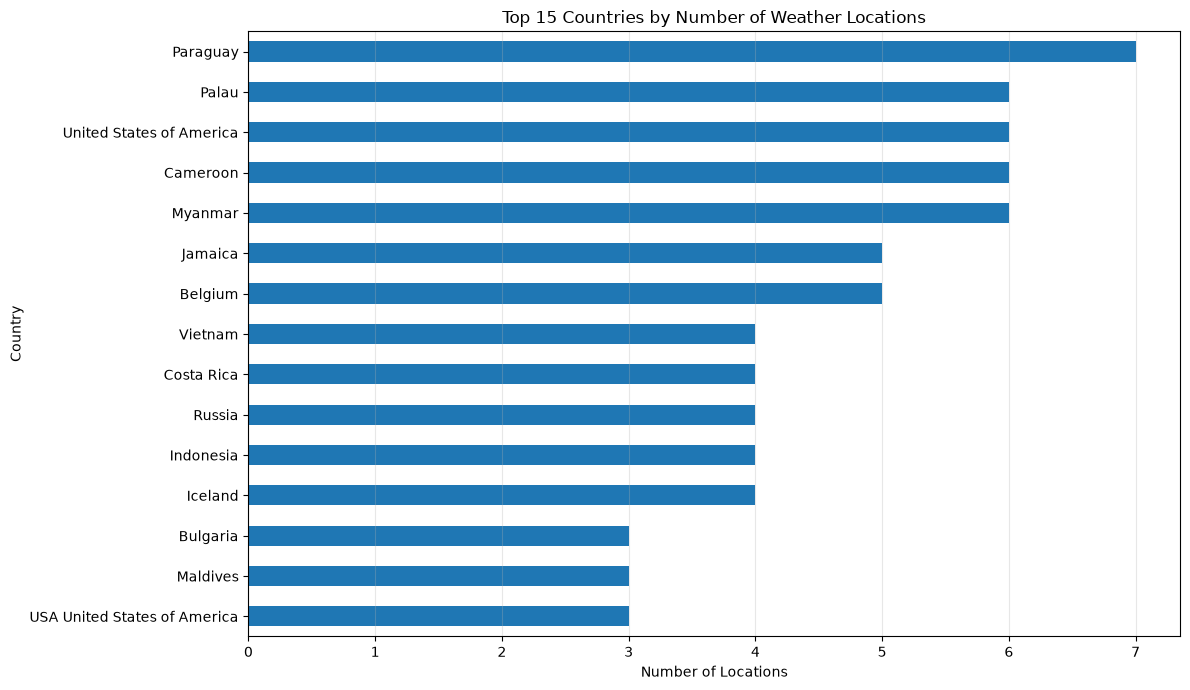

In [20]:
plot_locations_per_country(
    locations_per_country,
    save_path=FIGURES_DIR / "locations_per_country.png"
)

**Country-Level Spatial Distribution — Key Findings**

The dataset contains 211 countries with an average of 1.36 geographical locations per country.

Key observations:
- 176 countries (83.4%) have only one geographical location.
- Only 35 countries (16.6%) have more than one location.
- The highest number of locations in a single country is 7.
- Paraguay has the highest number of locations, with 7 locations.
- Geographical coverage is concentrated in a small number of locations within most countries.

**Data Quality Observation:**

Some country names appear under different naming formats, such as "USA United States of America" and "United States of America".

This may lead to incorrect country-level counts. Country-name standardization should therefore be considered before conducting further country-level analysis.

**Conclusion:**

The dataset provides broad international coverage, but its geographical sampling is sparse within most countries. This limitation should be considered when designing spatial machine learning experiments and evaluating model generalization.